In [ ]:
!pip install torch==2.1.0+cu121 torchvision==0.16.0+cu121 torchaudio==2.1.0 \
 --extra-index-url https://download.pytorch.org/whl/cu121


Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu121


In [ ]:
!pip uninstall numpy -y
!pip install numpy==1.26.4

Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4


  Using cached numpy-1.26.4-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)


In [ ]:
!pip install \
    torch-scatter \
    torch-sparse \
    torch-cluster \
    torch-spline-conv \
    -f https://data.pyg.org/whl/torch-2.1.0+cu121.html


Looking in links: https://data.pyg.org/whl/torch-2.1.0+cu121.html


In [ ]:
!pip install torch-geometric

In [ ]:
import torch
print(torch.__version__)
print(torch.version.cuda)

2.1.0+cu121
12.1


In [ ]:
# Install dependencies (run once)
!pip install pyvista torch torch-geometric numpy scikit-learn


In [ ]:
!pip install pyvista torch-geometric scipy


# Surface Pressure Predction using Geometry informed Neural Operator

In [ ]:
import os, gc, glob
import torch
import numpy as np
import pyvista as pv
from tqdm import tqdm
import matplotlib.pyplot as plt

from torch import nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import knn_graph
from torch_scatter import scatter_add

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:128"


/home/exouser/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [ ]:
class DrivAERPressureDataset(torch.utils.data.Dataset):
    def __init__(self, root):
        self.files = sorted(glob.glob(os.path.join(root, "*.vtk")))
        self.data = []

        for f in tqdm(self.files):
            mesh = pv.read(f)
            pos = torch.tensor(mesh.points, dtype=torch.float32)
            pressure = torch.tensor(mesh.point_data['p'], dtype=torch.float32).unsqueeze(1)

            x = torch.cat([pos, torch.zeros_like(pos)], dim=1)
            self.data.append(Data(x=x, y=pressure))

    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return self.data[idx]


In [ ]:
from torch_geometric.loader import DataLoader

dataset = DrivAERPressureDataset("/home/exouser/02_triangular_mesh_autoencoder/Dataset/drivAERnet_pressure")

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_set, test_set = torch.utils.data.random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_set, batch_size=1, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=1)


100%|██████████| 97/97 [00:47<00:00,  2.05it/s]


In [ ]:
class GraphEncoder(nn.Module):
    def __init__(self, in_dim, hidden):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim + 3, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden)
        )

    def forward(self, x, pos, edge_index):
        row, col = edge_index
        m = self.mlp(torch.cat([x[col], pos[col] - pos[row]], dim=1))
        return scatter_add(m, row, dim=0, dim_size=x.size(0))


class FNOBlock(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(width, width),
            nn.ReLU(),
            nn.Linear(width, width)
        )

    def forward(self, x):
        return self.net(x)


class GINO(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = GraphEncoder(6, 32)
        self.fno = FNOBlock(32)
        self.decoder = nn.Sequential(
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, data):
        pos = data.x[:, :3]
        edge_index = knn_graph(pos, k=16, loop=False)
        h = self.encoder(data.x, pos, edge_index)
        h = self.fno(h)
        return self.decoder(h)


## MSE loss

In [ ]:
ckpt_dir = "/home/exouser/02_triangular_mesh_autoencoder/Model/checkpoints_GiNO_6"
os.makedirs(ckpt_dir, exist_ok=True)

model = GINO().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses = []

for epoch in range(1, 101):
    model.train()
    total_loss = 0

    for data in train_loader:
        data = data.to(device)

        pred = model(data)
        loss = F.mse_loss(pred, data.y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg = total_loss / len(train_loader)
    train_losses.append(avg)

    if epoch % 1 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'loss': avg
        }, f"{ckpt_dir}/gino_epoch_{epoch}.pt")

    print(f"Epoch {epoch:03d} | Loss {avg:.6f}")


Epoch 001 | Loss 17650.309989
Epoch 002 | Loss 12569.059253
Epoch 003 | Loss 10878.731686
Epoch 004 | Loss 9772.560750
Epoch 005 | Loss 8579.149522
Epoch 006 | Loss 7718.291339
Epoch 007 | Loss 7390.976201
Epoch 008 | Loss 7138.038048
Epoch 009 | Loss 6965.726157
Epoch 010 | Loss 6805.357802
Epoch 011 | Loss 6670.248656
Epoch 012 | Loss 6574.211153
Epoch 013 | Loss 6473.227685
Epoch 014 | Loss 6308.482688
Epoch 015 | Loss 6259.728395
Epoch 016 | Loss 6153.080123
Epoch 017 | Loss 6084.208414
Epoch 018 | Loss 6067.839634
Epoch 019 | Loss 5956.231826
Epoch 020 | Loss 5882.649858
Epoch 021 | Loss 5821.954793
Epoch 022 | Loss 5802.876154
Epoch 023 | Loss 5750.581442
Epoch 024 | Loss 5776.952142
Epoch 025 | Loss 5721.987641


## relative L2 Loss

In [ ]:
import os
import gc
import torch
import torch.nn.functional as F

# ------------------------
# Memory safety
# ------------------------
gc.collect()
torch.cuda.empty_cache()
model = GINO().to(device)
# ------------------------
# Loss functions
# ------------------------
def relative_l2(pred, gt):
    return torch.norm(pred - gt) / (torch.norm(gt) + 1e-8)

# ------------------------
# Optimizer
# ------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# ------------------------
# Training setup
# ------------------------
ckpt_dir = "/home/exouser/02_triangular_mesh_autoencoder/Model/checkpoints_GiNO_L2"
os.makedirs(ckpt_dir, exist_ok=True)

num_epochs = 100
train_losses = []

# ------------------------
# Training loop
# ------------------------
for epoch in range(1, num_epochs + 1):
    model.train()
    total_loss = 0.0

    for data in train_loader:
        data = data.to(device)

        pred = model(data)

        # Improved physics-aware loss
        loss = relative_l2(pred, data.y) \
               + 1e-4 * torch.abs(pred.std() - data.y.std())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)

    # Save checkpoint every 10 epochs
    if epoch % 10 == 0:
        torch.save(
            {"model_state_dict": model.state_dict()},
            f"{ckpt_dir}/gino_epoch_{epoch}.pt"
        )

    print(f"Epoch {epoch:04d} | Loss: {avg_loss:.6f}")


Epoch 0001 | Loss: 0.896818
Epoch 0002 | Loss: 0.749218
Epoch 0003 | Loss: 0.696892
Epoch 0004 | Loss: 0.657570
Epoch 0005 | Loss: 0.610173
Epoch 0006 | Loss: 0.579272
Epoch 0007 | Loss: 0.565370
Epoch 0008 | Loss: 0.556032
Epoch 0009 | Loss: 0.546892
Epoch 0010 | Loss: 0.540284
Epoch 0011 | Loss: 0.537305
Epoch 0012 | Loss: 0.533531
Epoch 0013 | Loss: 0.527254
Epoch 0014 | Loss: 0.523038
Epoch 0015 | Loss: 0.520951
Epoch 0016 | Loss: 0.518674
Epoch 0017 | Loss: 0.516591
Epoch 0018 | Loss: 0.517334
Epoch 0019 | Loss: 0.514162
Epoch 0020 | Loss: 0.511750
Epoch 0021 | Loss: 0.506856
Epoch 0022 | Loss: 0.504861
Epoch 0023 | Loss: 0.504356
Epoch 0024 | Loss: 0.500712
Epoch 0025 | Loss: 0.500893
Epoch 0026 | Loss: 0.496088
Epoch 0027 | Loss: 0.495189
Epoch 0028 | Loss: 0.493887
Epoch 0029 | Loss: 0.495972
Epoch 0030 | Loss: 0.490488
Epoch 0031 | Loss: 0.491822
Epoch 0032 | Loss: 0.488808
Epoch 0033 | Loss: 0.488833
Epoch 0034 | Loss: 0.491973
Epoch 0035 | Loss: 0.485144
Epoch 0036 | Loss: 0

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("GiNO Training Convergence")
plt.grid(True)
plt.show()

/home/exouser/.venv/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


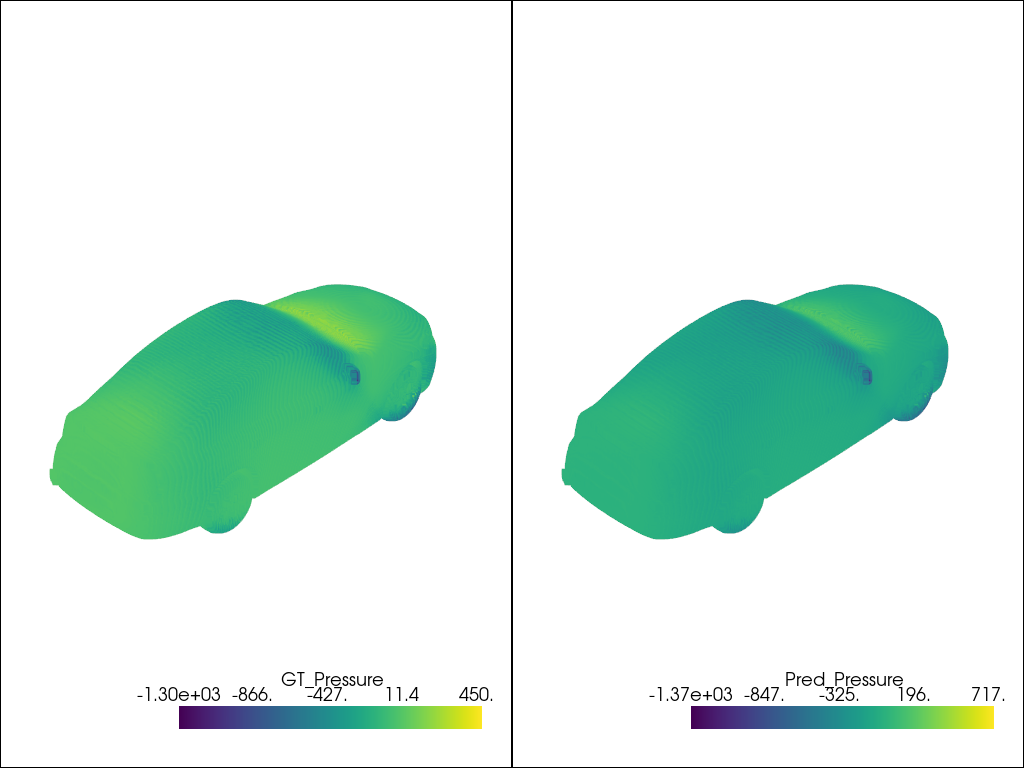

In [ ]:
import gc
gc.collect()
torch.cuda.empty_cache()

# Path to your checkpoint
ckpt_path = "/home/exouser/02_triangular_mesh_autoencoder/Model/checkpoints_GiNO_L2/gino_epoch_150.pt"
model=GINO().to(device)
# Load model
model.eval()
ckpt = torch.load(ckpt_path, map_location=device)
model.load_state_dict(ckpt['model_state_dict'])

# Get one test sample
data = next(iter(test_loader))

x = data.x
pos = x[:, :3]
gt = data.y.numpy().squeeze()

# Chunked inference
chunk_size = 4000
pred_list = []

with torch.no_grad():
    for i in range(0, x.shape[0], chunk_size):
        fake = Data(x=x[i:i+chunk_size].to(device))
        p = model(fake).cpu()
        pred_list.append(p)

pred = torch.cat(pred_list, dim=0).numpy().squeeze()

# Visualization
mesh = pv.PolyData(pos.numpy())
mesh["GT_Pressure"] = gt
mesh["Pred_Pressure"] = pred

p = pv.Plotter(shape=(1,2))
p.add_mesh(mesh, scalars="GT_Pressure")
p.subplot(0,1)
p.add_mesh(mesh, scalars="Pred_Pressure")
p.show()


/home/exouser/.venv/lib/python3.10/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


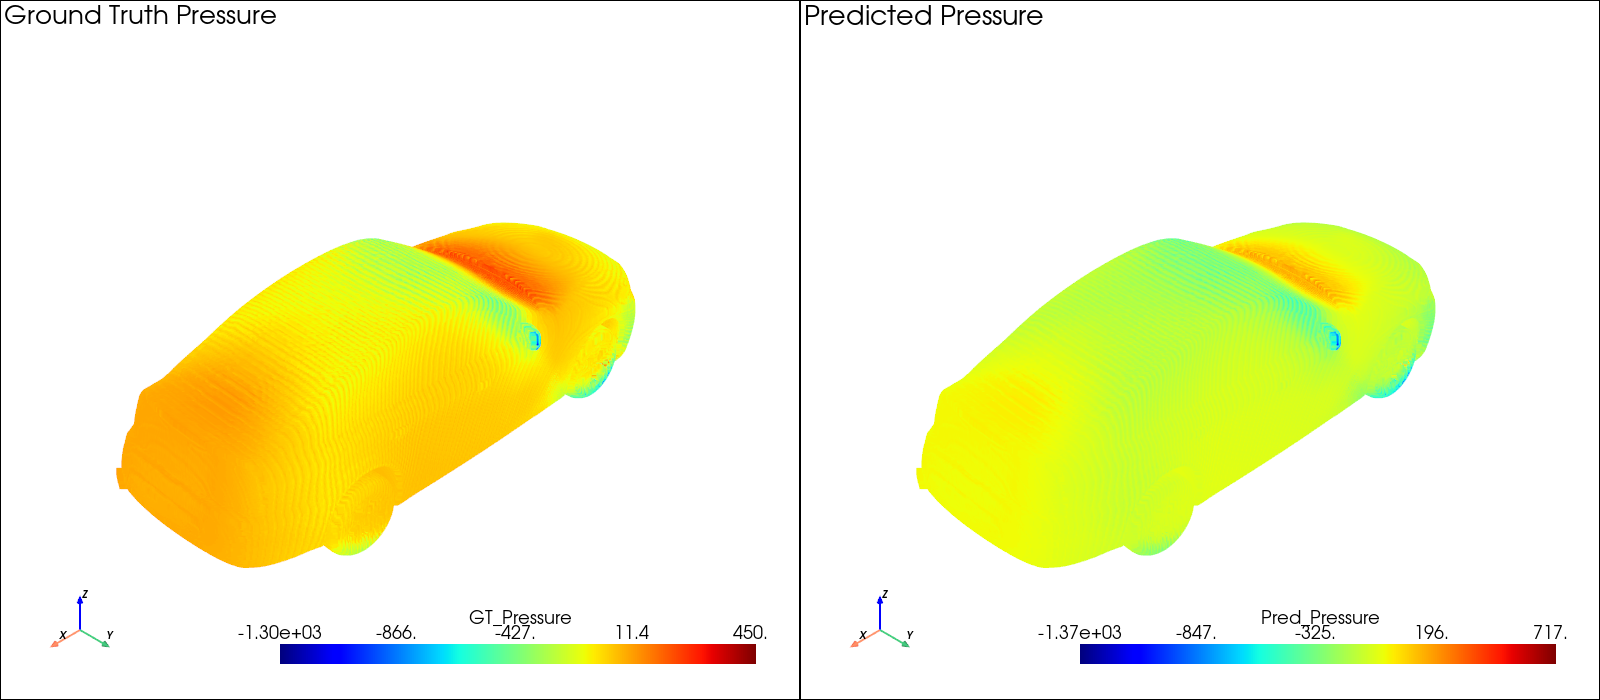

In [ ]:
# High-quality 3D visualization
p = pv.Plotter(shape=(1, 2), window_size=(1600, 700))

# Left: Ground Truth
p.subplot(0, 0)
p.add_text("Ground Truth Pressure", font_size=12)
p.add_mesh(
    mesh,
    scalars="GT_Pressure",
    cmap="jet",
    show_scalar_bar=True,
    lighting=True,
    smooth_shading=True
)
p.add_axes()

# Right: Prediction
p.subplot(0, 1)
p.add_text("Predicted Pressure", font_size=12)
p.add_mesh(
    mesh,
    scalars="Pred_Pressure",
    cmap="jet",
    show_scalar_bar=True,
    lighting=True,
    smooth_shading=True
)
p.add_axes()

# Synchronize camera for both views
p.link_views()

# Better camera angle
p.view_isometric()
p.show()


In [ ]:
# ===========================
# Resume Training for +100 Epochs
# ===========================

import torch
import os
import gc

# Memory safety
gc.collect()
torch.cuda.empty_cache()

# Load model
model = GINO().to(device)
ckpt_path = "/home/exouser/02_triangular_mesh_autoencoder/Model/checkpoints_GiNO_L2/gino_epoch_150.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

# Recreate optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
train_losses = []
# Training settings
start_epoch = 150
extra_epochs = 100
end_epoch = start_epoch + extra_epochs - 1

ckpt_dir = "/home/exouser/02_triangular_mesh_autoencoder/Model/checkpoints_GiNO_L2"
os.makedirs(ckpt_dir, exist_ok=True)

print(f"Resuming training from epoch {start_epoch} → {end_epoch}")
def relative_l2(pred, gt):
    return torch.norm(pred - gt) / (torch.norm(gt) + 1e-8)

# ------------------------
# Optimizer
# ------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# Training loop
for epoch in range(start_epoch, end_epoch + 1):
    model.train()
    total_loss = 0.0

    for data in train_loader:
        data = data.to(device)

        pred = model(data)

        loss = relative_l2(pred, data.y) \
               + 1e-4 * torch.abs(pred.std() - data.y.std())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)

    if epoch % 10 == 0:
        torch.save(
            {"model_state_dict": model.state_dict()},
            f"{ckpt_dir}/gino_epoch_{epoch}.pt"
        )

    print(f"Epoch {epoch:04d} | Loss: {avg_loss:.6f}")


In [ ]:
import torch
import torch.nn.functional as F
import gc
import pyvista as pv
from torch_geometric.data import Data

# ------------------------
# Memory cleanup
# ------------------------
gc.collect()
torch.cuda.empty_cache()

# ------------------------
# Load model
# ------------------------
ckpt_path = "/home/exouser/02_triangular_mesh_autoencoder/Model/checkpoints_GiNO_L2/gino_epoch_150.pt"
model = GINO().to(device)
model.eval()

ckpt = torch.load(ckpt_path, map_location=device)
model.load_state_dict(ckpt['model_state_dict'])

# ------------------------
# Evaluation on test set
# ------------------------
all_preds = []
all_gt = []

with torch.no_grad():
    for data in test_loader:
        data = data.to(device)
        x = data.x
        # Chunked inference to save memory
        chunk_size = 4000
        pred_list = []
        for i in range(0, x.shape[0], chunk_size):
            chunk = Data(x=x[i:i+chunk_size].to(device))
            p = model(chunk).cpu()
            pred_list.append(p)
        pred = torch.cat(pred_list, dim=0)
        all_preds.append(pred)
        all_gt.append(data.y.cpu())

# Concatenate all test data
all_preds = torch.cat(all_preds, dim=0)
all_gt = torch.cat(all_gt, dim=0)

# ------------------------
# Metric calculations
# ------------------------
# Relative L2 Error
rel_l2 = torch.norm(all_preds - all_gt) / (torch.norm(all_gt) + 1e-8)

# Standard Deviation Error
std_error = torch.abs(all_preds.std() - all_gt.std())

# Max and Min point-wise error
pointwise_error = torch.abs(all_preds - all_gt)
max_error = pointwise_error.max()
min_error = pointwise_error.min()

# ------------------------
# Print results
# ------------------------
print("Evaluation Metrics on Test Set:")
print(f"Relative L2 Error       : {rel_l2.item():.6f}")
print(f"Standard Deviation Error: {std_error.item():.6f}")
print(f"Max Point-wise Error    : {max_error.item():.6f}")
print(f"Min Point-wise Error    : {min_error.item():.6f}")


Evaluation Metrics on Test Set:
Relative L2 Error       : 0.558833
Standard Deviation Error: 28.420113
Max Point-wise Error    : 2168.992920
Min Point-wise Error    : 0.000000
